# Equality Comparison Notebook

Run the setup cells once. Then create a new cell and call `compare_runs(path_a, path_b)` with two run folders or two `tc*` folders.

Examples:

```python
compare_runs('results_BBOX/OrigServer_runA', 'results_BBOX/OrigServer_runB')
compare_runs('results_BBOX/SpeedTest_runDiffracA/tc1', 'results_BBOX/SpeedTest_runDiffracB/tc1')
```


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)

DEFAULT_TC = 'tc1'


In [2]:
def _resolve_tc_folder(path, tc=DEFAULT_TC):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    if path.is_file():
        raise ValueError(f'Expected a directory, got file: {path}')

    if any(path.glob('snr_results_*.csv')) or any(path.glob('throughput_results_*.csv')):
        return path

    tc_folder = path / tc
    if tc_folder.exists():
        return tc_folder

    tc_dirs = sorted(p for p in path.glob('tc*') if p.is_dir())
    if len(tc_dirs) == 1:
        return tc_dirs[0]

    raise FileNotFoundError(f'Could not find {tc} or a unique tc* folder under {path}')


def _find_csv(folder, prefix):
    matches = sorted(Path(folder).glob(f'{prefix}_*.csv'))
    if not matches:
        raise FileNotFoundError(f'No {prefix}_*.csv found in {folder}')
    if len(matches) > 1:
        print(f'Warning: found {len(matches)} {prefix} files in {folder}; using newest by mtime')
        matches = sorted(matches, key=lambda p: p.stat().st_mtime)
    return matches[-1]


def _read_snr(folder):
    path = _find_csv(folder, 'snr_results')
    frame = pd.read_csv(path)
    rename = {
        'Time_s': 'time_s',
        'STA_NodeId': 'sta_node_id',
        'PathLoss_dB': 'pathloss_db',
        'RxPower_dBm': 'rx_power_dbm',
        'SNR_dB': 'snr_db',
        'RxStatus': 'rx_status',
        'PacketUid': 'packet_uid',
        'PacketSize_Bytes': 'packet_size_bytes',
        'FailureReason': 'failure_reason',
    }
    frame = frame.rename(columns=rename)
    for col in ['time_s', 'pos_x', 'pos_y', 'pos_z', 'pathloss_db', 'rx_power_dbm', 'snr_db']:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors='coerce')
    for col in ['sta_node_id', 'packet_uid', 'packet_size_bytes']:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors='coerce').astype('Int64')
    frame.attrs['path'] = path
    return frame


def _read_throughput(folder):
    path = _find_csv(folder, 'throughput_results')
    frame = pd.read_csv(path)
    frame = frame.rename(columns={'Time': 'time_s', 'Throughput_Mbps': 'throughput_mbps'})
    frame['time_s'] = pd.to_numeric(frame['time_s'], errors='coerce')
    frame['throughput_mbps'] = pd.to_numeric(frame['throughput_mbps'], errors='coerce')
    frame.attrs['path'] = path
    return frame


def load_run(path, label=None, tc=DEFAULT_TC):
    folder = _resolve_tc_folder(path, tc=tc)
    return {
        'label': label or folder.parent.name,
        'folder': folder,
        'snr': _read_snr(folder),
        'throughput': _read_throughput(folder),
    }


In [3]:
def _finite_mean(series):
    values = pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    return float(values.mean()) if len(values) else np.nan


def _finite_max(series):
    values = pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    return float(values.max()) if len(values) else np.nan


def _first_deviation(frame, delta_col, time_col='time_s', tol=1e-9):
    if frame.empty or delta_col not in frame.columns:
        return None
    valid = frame[np.isfinite(frame[delta_col]) & (frame[delta_col].abs() > tol)].copy()
    if valid.empty:
        return None
    valid = valid.sort_values(time_col)
    return valid.iloc[0]


def _max_deviation(frame, delta_col):
    if frame.empty or delta_col not in frame.columns:
        return None
    valid = frame[np.isfinite(frame[delta_col])].copy()
    if valid.empty:
        return None
    return valid.loc[valid[delta_col].abs().idxmax()]


def _align_snr_by_packet_uid(run_a, run_b):
    snr_a = run_a['snr'].dropna(subset=['packet_uid']).copy()
    snr_b = run_b['snr'].dropna(subset=['packet_uid']).copy()
    merged = snr_a.merge(snr_b, on='packet_uid', suffixes=('_a', '_b'), how='inner')
    if merged.empty:
        return merged
    merged['time_s'] = merged[['time_s_a', 'time_s_b']].mean(axis=1)
    merged['delta_time_s'] = (merged['time_s_a'] - merged['time_s_b']).abs()
    merged['delta_snr_db'] = (merged['snr_db_a'] - merged['snr_db_b']).abs()
    merged['delta_pathloss_db'] = (merged['pathloss_db_a'] - merged['pathloss_db_b']).abs()
    for axis in ['x', 'y', 'z']:
        col_a = f'pos_{axis}_a'
        col_b = f'pos_{axis}_b'
        if col_a in merged.columns and col_b in merged.columns:
            merged[f'delta_pos_{axis}'] = (merged[col_a] - merged[col_b]).abs()
    pos_delta_cols = [c for c in merged.columns if c.startswith('delta_pos_')]
    if pos_delta_cols:
        merged['delta_pos_m'] = merged[pos_delta_cols].max(axis=1)
    return merged.sort_values('time_s')


def _align_throughput(run_a, run_b):
    a = run_a['throughput'].reset_index(drop=True).copy()
    b = run_b['throughput'].reset_index(drop=True).copy()

    if len(a) == len(b) and np.allclose(a['time_s'], b['time_s'], equal_nan=True):
        merged = pd.DataFrame({
            'time_s': a['time_s'],
            'throughput_mbps_a': a['throughput_mbps'],
            'throughput_mbps_b': b['throughput_mbps'],
        })
    else:
        aa = a.assign(time_key=a['time_s'].round(6)).groupby('time_key', as_index=False)['throughput_mbps'].mean()
        bb = b.assign(time_key=b['time_s'].round(6)).groupby('time_key', as_index=False)['throughput_mbps'].mean()
        merged = aa.merge(bb, on='time_key', suffixes=('_a', '_b'), how='inner')
        merged = merged.rename(columns={'time_key': 'time_s'})

    merged['delta_throughput_mbps'] = (merged['throughput_mbps_a'] - merged['throughput_mbps_b']).abs()
    return merged.sort_values('time_s')


In [4]:
def _summary_table(run_a, run_b, snr_cmp, tp_cmp, snr_tol, throughput_tol):
    first_snr = _first_deviation(snr_cmp, 'delta_snr_db', tol=snr_tol)
    first_pathloss = _first_deviation(snr_cmp, 'delta_pathloss_db', tol=snr_tol)
    first_tp = _first_deviation(tp_cmp, 'delta_throughput_mbps', tol=throughput_tol)
    max_snr = _max_deviation(snr_cmp, 'delta_snr_db')
    max_pathloss = _max_deviation(snr_cmp, 'delta_pathloss_db')
    max_tp = _max_deviation(tp_cmp, 'delta_throughput_mbps')

    def value(row, column):
        if row is None or column not in row.index:
            return np.nan
        return row[column]

    rows = [
        ('snr rows', len(run_a['snr']), len(run_b['snr']), len(snr_cmp), np.nan, np.nan, np.nan),
        ('common PacketUid', np.nan, np.nan, len(snr_cmp), np.nan, np.nan, np.nan),
        ('average SNR dB', _finite_mean(run_a['snr']['snr_db']), _finite_mean(run_b['snr']['snr_db']), np.nan, _finite_mean(snr_cmp['delta_snr_db']) if 'delta_snr_db' in snr_cmp else np.nan, value(first_snr, 'time_s'), value(max_snr, 'delta_snr_db')),
        ('average pathloss dB', _finite_mean(run_a['snr']['pathloss_db']), _finite_mean(run_b['snr']['pathloss_db']), np.nan, _finite_mean(snr_cmp['delta_pathloss_db']) if 'delta_pathloss_db' in snr_cmp else np.nan, value(first_pathloss, 'time_s'), value(max_pathloss, 'delta_pathloss_db')),
        ('average throughput Mbps', _finite_mean(run_a['throughput']['throughput_mbps']), _finite_mean(run_b['throughput']['throughput_mbps']), len(tp_cmp), _finite_mean(tp_cmp['delta_throughput_mbps']) if 'delta_throughput_mbps' in tp_cmp else np.nan, value(first_tp, 'time_s'), value(max_tp, 'delta_throughput_mbps')),
    ]
    summary = pd.DataFrame(rows, columns=['metric', run_a['label'], run_b['label'], 'aligned_rows', 'average_deviation', 'first_deviation_time_s', 'maximum_deviation'])
    return summary


def _print_file_info(run_a, run_b):
    print(f"A: {run_a['label']} -> {run_a['folder']}")
    print(f"   SNR: {run_a['snr'].attrs.get('path')}")
    print(f"   Throughput: {run_a['throughput'].attrs.get('path')}")
    print(f"B: {run_b['label']} -> {run_b['folder']}")
    print(f"   SNR: {run_b['snr'].attrs.get('path')}")
    print(f"   Throughput: {run_b['throughput'].attrs.get('path')}")


In [5]:
def _mark_max(ax, frame, delta_col, y_col, label):
    row = _max_deviation(frame, delta_col)
    if row is None:
        return
    ax.scatter([row['time_s']], [row[y_col]], color='crimson', zorder=5)
    ax.annotate(
        f"max {label}={row[delta_col]:.4g}",
        xy=(row['time_s'], row[y_col]),
        xytext=(8, 8),
        textcoords='offset points',
        color='crimson',
        fontsize=9,
    )


def _mark_first(ax, frame, delta_col, tol, label):
    row = _first_deviation(frame, delta_col, tol=tol)
    if row is None:
        return
    ax.axvline(row['time_s'], color='crimson', linestyle='--', alpha=0.5, linewidth=1)
    ax.text(row['time_s'], 0.98, label, transform=ax.get_xaxis_transform(), rotation=90, va='top', ha='right', color='crimson', fontsize=9)


def _plot_comparison(run_a, run_b, snr_cmp, tp_cmp, snr_tol, throughput_tol):
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
    ax_snr, ax_tp, ax_snr_delta, ax_tp_delta = axes.ravel()

    for run, color in [(run_a, 'tab:blue'), (run_b, 'tab:orange')]:
        snr = run['snr'].sort_values('time_s')
        finite = snr[np.isfinite(snr['snr_db'])]
        ax_snr.plot(finite['time_s'], finite['snr_db'], '.', markersize=3, alpha=0.55, label=run['label'], color=color)

        tp = run['throughput'].sort_values('time_s')
        ax_tp.plot(tp['time_s'], tp['throughput_mbps'], linewidth=1.6, label=run['label'], color=color)

    ax_snr.set_title('SNR over time')
    ax_snr.set_xlabel('time [s]')
    ax_snr.set_ylabel('SNR [dB]')
    ax_snr.grid(True, alpha=0.25)
    ax_snr.legend()

    ax_tp.set_title('Throughput over time')
    ax_tp.set_xlabel('time [s]')
    ax_tp.set_ylabel('throughput [Mbps]')
    ax_tp.grid(True, alpha=0.25)
    ax_tp.legend()

    if not snr_cmp.empty:
        ax_snr_delta.plot(snr_cmp['time_s'], snr_cmp['delta_snr_db'], '.', markersize=3, alpha=0.6, color='tab:green')
        _mark_max(ax_snr_delta, snr_cmp, 'delta_snr_db', 'delta_snr_db', 'dSNR')
        _mark_first(ax_snr, snr_cmp, 'delta_snr_db', snr_tol, 'first SNR deviation')
    ax_snr_delta.set_title('SNR absolute deviation by common PacketUid')
    ax_snr_delta.set_xlabel('time [s]')
    ax_snr_delta.set_ylabel('|delta SNR| [dB]')
    ax_snr_delta.grid(True, alpha=0.25)

    if not tp_cmp.empty:
        ax_tp_delta.plot(tp_cmp['time_s'], tp_cmp['delta_throughput_mbps'], linewidth=1.4, color='tab:purple')
        _mark_max(ax_tp_delta, tp_cmp, 'delta_throughput_mbps', 'delta_throughput_mbps', 'dTP')
        _mark_first(ax_tp, tp_cmp, 'delta_throughput_mbps', throughput_tol, 'first TP deviation')
    ax_tp_delta.set_title('Throughput absolute deviation')
    ax_tp_delta.set_xlabel('time [s]')
    ax_tp_delta.set_ylabel('|delta throughput| [Mbps]')
    ax_tp_delta.grid(True, alpha=0.25)

    fig.suptitle(f"{run_a['label']} vs {run_b['label']}", fontsize=14)
    return fig, axes


In [6]:
def compare_runs(path_a, path_b, label_a=None, label_b=None, tc=DEFAULT_TC, snr_tol=1e-6, throughput_tol=1e-9, show_files=True):
    """Compare two run folders or two tc* folders.

    Returns a dictionary containing the loaded runs, aligned comparison tables,
    summary table, and Matplotlib figure.
    """
    run_a = load_run(path_a, label=label_a, tc=tc)
    run_b = load_run(path_b, label=label_b, tc=tc)
    snr_cmp = _align_snr_by_packet_uid(run_a, run_b)
    tp_cmp = _align_throughput(run_a, run_b)
    summary = _summary_table(run_a, run_b, snr_cmp, tp_cmp, snr_tol, throughput_tol)

    if show_files:
        _print_file_info(run_a, run_b)

    display(summary)
    fig, axes = _plot_comparison(run_a, run_b, snr_cmp, tp_cmp, snr_tol, throughput_tol)

    return {
        'run_a': run_a,
        'run_b': run_b,
        'snr_comparison': snr_cmp,
        'throughput_comparison': tp_cmp,
        'summary': summary,
        'figure': fig,
        'axes': axes,
    }


## Example Calls

Copy one of these into a new cell and change the paths. The paths can point either to a run folder or directly to a `tc*` folder.

A: SpeedTest_runG -> results_BBOX\SpeedTest_runG\tc1
   SNR: results_BBOX\SpeedTest_runG\tc1\snr_results_1_1_runG_20260508_170556_2544110.csv
   Throughput: results_BBOX\SpeedTest_runG\tc1\throughput_results_1_1_runG_20260508_170556_2544110.csv
B: SpeedTest_runNoRegDiffracB -> results_BBOX\SpeedTest_runNoRegDiffracB\tc1
   SNR: results_BBOX\SpeedTest_runNoRegDiffracB\tc1\snr_results_1_1_runNoRegDiffracB_20260509_221534_2806928.csv
   Throughput: results_BBOX\SpeedTest_runNoRegDiffracB\tc1\throughput_results_1_1_runNoRegDiffracB_20260509_221534_2806928.csv


,metric,SpeedTest_runG,SpeedTest_runNoRegDiffracB,aligned_rows,average_deviation,first_deviation_time_s,maximum_deviation
0,snr rows,17064.000000,17191.000000,16754.0,NaN,NaN,NaN
1,common PacketUid,NaN,NaN,16754.0,NaN,NaN,NaN
2,average SNR dB,48.351050,48.172799,NaN,0.003337,1.00701,17.9297
3,average pathloss dB,59.069580,59.303640,NaN,0.000066,1.00701,0.0127
4,average throughput Mbps,243.884319,244.141293,988.0,2.337320,8.80000,190.7710


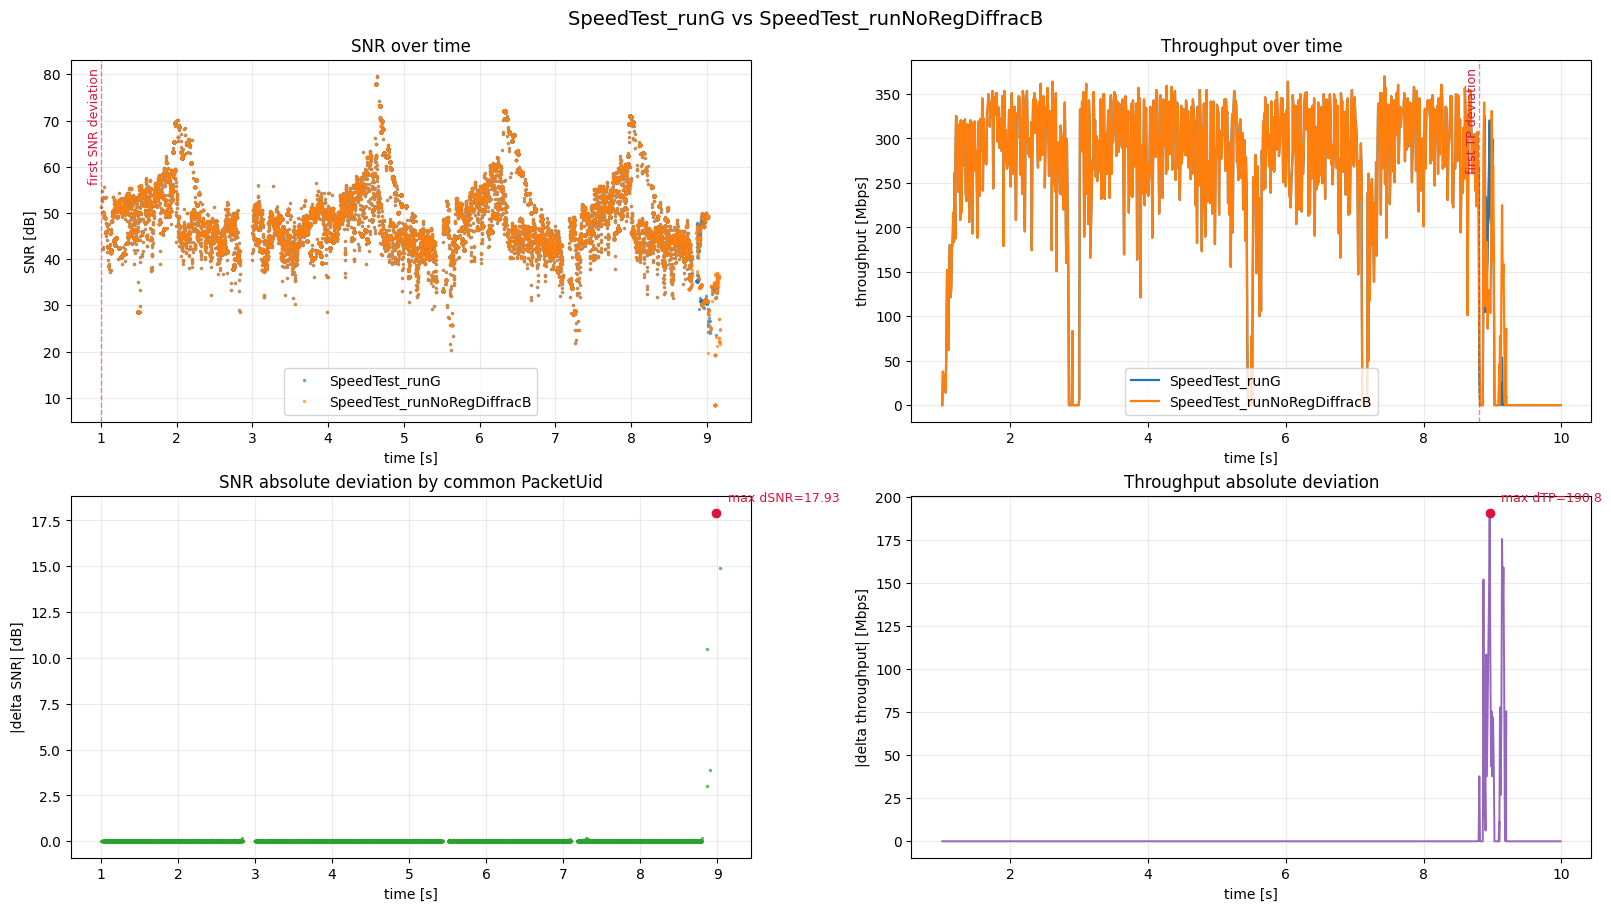

In [12]:
# Original server pair
# result = compare_runs('results_BBOX/OrigServer_runA', 'results_BBOX/OrigServer_runB')

# Full diffraction pair
# result = compare_runs('results_BBOX/SpeedTest_runDiffracA', 'results_BBOX/SpeedTest_runDiffracB')

# Base diffraction without edge diffraction
result = compare_runs('results_BBOX/SpeedTest_runG', 'results_BBOX/SpeedTest_runNoRegDiffracB')
